In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [5]:
import math
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- Numpy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

In [23]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m','nparents1','nparents2']

In [24]:
files = ['/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_50pthat1000_rc_truth.txt']

In [25]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [26]:
df = applyCut(df, 'pt>20')
df.eval('b_ch = q1*q2', inplace=True)

In [8]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 590165
number of jets with q1 == +1: 847841


In [9]:
np.unique(np.concatenate([np.asarray(df['pid1']),np.asarray(df['pid2'])]))

array([-5224, -5222, -5132, -5114, -5112, -4324, -4322, -4232, -4224,
       -4222, -4214, -4212, -4122, -3334, -3314, -3312, -3224, -3222,
       -3114, -3112, -2224, -2214, -2212, -1114,  -543,  -523,  -521,
        -433,  -431,  -413,  -411,  -323,  -321,  -213,  -211,   -15,
         -13,   -11,    11,    13,    15,   211,   213,   321,   323,
         411,   413,   431,   433,   521,   523,  1114,  2212,  2214,
        2224,  3112,  3114,  3222,  3224,  3312,  3314,  3334,  4122,
        4212,  4214,  4222,  4224,  4232,  4322,  4324,  5112,  5114,
        5132,  5222,  5224])

In [10]:
np.unique(np.concatenate([np.asarray(df['parent1']),np.asarray(df['parent2'])]))

array([-999,  -15,  -13,  -11,   11,   13,   15, 1103, 2101, 2103, 2203,
       3101, 3103, 3201, 3203, 4101, 4103, 4201, 4203, 4403, 5103])

In [11]:
np.unique(np.concatenate([np.asarray(df['nparents1']),np.asarray(df['nparents2'])]))

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 46])

In [48]:
df = applyCut(df, 'abs(parent1)>15 and abs(parent2)>15 and abs(pid1)>15 and abs(pid2)>15')

In [36]:
np.unique(np.concatenate([np.asarray(df['nparents1']),np.asarray(df['nparents2'])]))

array([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18,
       19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
       36, 37, 38, 39, 40, 41, 42, 43, 46])

In [18]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [19]:
nodecay_rc_array = []
nodecay_rc_err_array = []
for i in range(0, len(df_array)):
    nodecay_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    nodecay_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [13]:
df_array = []
for i in range(1, 6):
    df_array.append(df[(df.n>2*i) & (df.n<2*(i+1))])

In [14]:
nodecay_rc_array = []
nodecay_rc_err_array = []
for i in range(0, len(df_array)):
    nodecay_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    nodecay_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [28]:
y_nodecay, yerr_nodecay = calc_hist(df['n'], bins=np.arange(2,16), weights=df['w'], density=True)[:2]

In [29]:
print(y_nodecay)
print(yerr_nodecay)

[1.34996459e-02 7.82571811e-02 1.81218692e-01 2.36245967e-01
 2.08879092e-01 1.42679077e-01 8.06590757e-02 3.65953057e-02
 1.51628514e-02 4.96781529e-03 1.22884674e-03 4.29180144e-04
 1.66457158e-04]
[7.62297625e-04 1.87349649e-03 2.73958553e-03 3.10173263e-03
 3.09698296e-03 2.46601731e-03 1.89907816e-03 1.07365245e-03
 8.28297675e-04 4.01081755e-04 1.22674819e-04 5.74303017e-05
 4.85287859e-05]


In [13]:
print(weighted_avg_and_std(df['n'], weights=df['w']))

(5.623654762183312, 1.7258544872494033)


In [41]:
files = ['/gpfs/gibbs/project/havener/ys668/rc/pythia_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_50pthat1000_rc_truth.txt']

In [42]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [43]:
df = applyCut(df, 'pt>20')
df.eval('b_ch = q1*q2', inplace=True)

In [23]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [24]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [20]:
df_array = []
for i in range(1, 6):
    df_array.append(df[(df.n>2*i) & (df.n<2*(i+1))])

In [21]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [44]:
y, yerr = calc_hist(df['n'], bins=np.arange(2,16), weights=df['w'], density=True)[:2]

In [18]:
print(weighted_avg_and_std(df['n'], weights=df['w']))

(7.1202150787426595, 2.212683736363809)


In [45]:
print(y)
print(yerr)

[0.00315009 0.02482279 0.07831256 0.13752966 0.17824023 0.17924707
 0.15006869 0.10690838 0.06826382 0.03844905 0.01959886 0.00864316
 0.00590993]
[0.00023372 0.0008344  0.00185988 0.00218733 0.00253783 0.00260933
 0.00241953 0.0020676  0.00162248 0.00128189 0.00094572 0.00043967
 0.0003945 ]


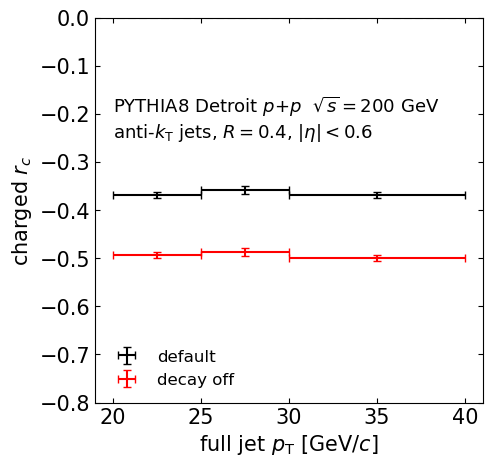

In [27]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='default', color='k')
plt.errorbar([22.5, 27.5, 35], nodecay_rc_array, xerr=[2.5, 2.5, 5], yerr=nodecay_rc_err_array, capsize=3, ls='none', label='decay off', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'PYTHIA8 Detroit $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-0.8,0)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

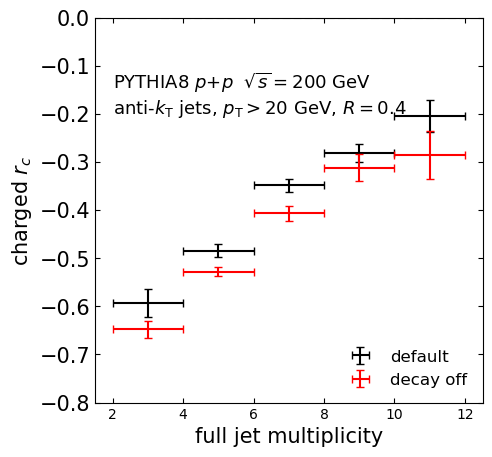

In [23]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(np.arange(3, 13, 2), rc_array, xerr=1, yerr=rc_err_array, capsize=3, ls='none', label='default', color='k')
plt.errorbar(np.arange(3, 13, 2), nodecay_rc_array, xerr=1, yerr=nodecay_rc_err_array, capsize=3, ls='none', label='decay off', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet multiplicity', fontsize=15)
plt.text(2,-0.2,'PYTHIA8 Detroit $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $p_{\mathrm{T}}>20$ GeV, $R=0.4$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-0.8,0)
plt.legend(fontsize=12, loc='lower right', frameon=False)
#plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

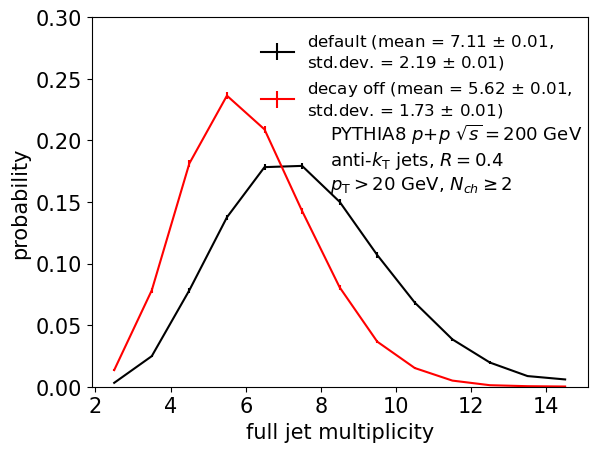

In [48]:
plt.errorbar(np.arange(2.5, 15.5), y, yerr=yerr, color='k', label='default (mean = 7.11 $\pm$ 0.01,\nstd.dev. = 2.19 $\pm$ 0.01)')
plt.errorbar(np.arange(2.5, 15.5), y_nodecay, yerr=yerr_nodecay, color='r', label='decay off (mean = 5.62 $\pm$ 0.01,\nstd.dev. = 1.73 $\pm$ 0.01)')
plt.xlabel(r'full jet multiplicity', fontsize=15)
plt.ylabel('probability', fontsize=15)
plt.text(8.25, 0.16,'PYTHIA8 $p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$\n$p_{\mathrm{T}}>20$ GeV, $N_{ch}\geq2$', fontsize=13)
plt.ylim(0,0.3)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.legend(fontsize=12, loc='upper right', frameon=False)

In [37]:
observables = ['evid','xsec','pt','n','parton','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m','nparents1','nparents2']

In [38]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_nodecay_11pthat15_rc_truth_theory.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_nodecay_15pthat20_rc_truth_theory.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_nodecay_20pthat25_rc_truth_theory.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_nodecay_25pthat30_rc_truth_theory.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_nodecay_30pthat35_rc_truth_theory.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_nodecay_35pthat40_rc_truth_theory.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_nodecay_40pthat45_rc_truth_theory.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_nodecay_45pthat50_rc_truth_theory.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_nodecay_50pthat1000_rc_truth_theory.txt']

In [39]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [40]:
df = applyCut(df, 'pt>20')
df.eval('b_ch = q1*q2', inplace=True)

In [41]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 197403
number of jets with q1 == +1: 266398


In [42]:
np.unique(np.concatenate([np.asarray(df['pid1']),np.asarray(df['pid2'])]))

array([-5224, -5222, -5132, -5114, -5112, -4324, -4322, -4232, -4224,
       -4222, -4214, -4212, -4122, -3334, -3314, -3312, -3224, -3222,
       -3114, -3112, -2224, -2214, -2212, -1114,  -523,  -521,  -433,
        -431,  -413,  -411,  -323,  -321,  -213,  -211,   -15,   -13,
         -11,    11,    13,    15,   211,   213,   321,   323,   411,
         413,   431,   433,   521,   523,  1114,  2212,  2214,  2224,
        3112,  3114,  3222,  3224,  3312,  3314,  3334,  4122,  4212,
        4214,  4222,  4224,  4232,  4322,  4324,  5112,  5114,  5132,
        5222,  5224])

In [43]:
np.unique(np.concatenate([np.asarray(df['parent1']),np.asarray(df['parent2'])]))

array([-999,  -15,  -13,  -11,   11,   13,   15, 1103, 2101, 2103, 2203,
       3101, 3103, 3201, 3203, 4101, 4103, 4201, 4203, 5103])

In [44]:
np.unique(np.concatenate([np.asarray(df['nparents1']),np.asarray(df['nparents2'])]))

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 40, 43])

In [45]:
df = applyCut(df, 'abs(parent1)>15 and abs(parent2)>15 and abs(pid1)>15 and abs(pid2)>15')

In [46]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [47]:
nodecay_rc_array = []
nodecay_rc_err_array = []
for i in range(0, len(df_array)):
    nodecay_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    nodecay_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [49]:
observables = ['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
               'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
               'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale']

In [48]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_11pthat15_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_15pthat20_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_20pthat25_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_25pthat30_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_30pthat35_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_35pthat40_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_40pthat45_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_45pthat50_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_50pthat1000_rc.txt']

In [50]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [52]:
df = applyCut(df, 'pt>20 and b!=0 and b!=-9')

In [53]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [54]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b')[1])

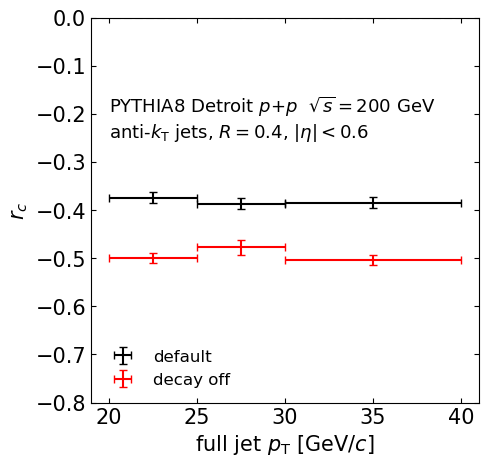

In [55]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='default', color='k')
plt.errorbar([22.5, 27.5, 35], nodecay_rc_array, xerr=[2.5, 2.5, 5], yerr=nodecay_rc_err_array, capsize=3, ls='none', label='decay off', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'PYTHIA8 Detroit $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$', fontsize=15)
plt.ylim(-0.8,0)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

In [21]:
parent1_new = []
parent2_new = []
for i in range(0, df.shape[0]):
    parent1 = df.iloc[i]['parent1']
    parent2 = df.iloc[i]['parent2']
    if (parent1 in diquark_array):
        parent1_new.append(-998)
    else:
        parent1_new.append(parent1)
    if (parent2 in diquark_array):
        parent2_new.append(-998)
    else:
        parent2_new.append(parent2)

In [22]:
df['parent1_new'] = parent1_new
df['parent2_new'] = parent2_new

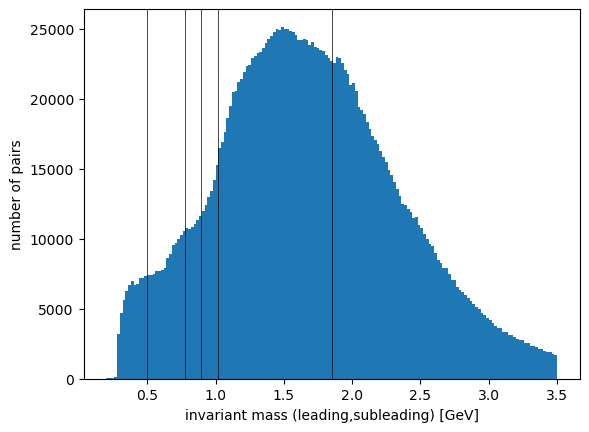

In [23]:
plt.hist(df['m'], bins=np.arange(0.2, 3.52, 0.02))
plt.xlabel('invariant mass (leading,subleading) [GeV]')
plt.ylabel('number of pairs')
plt.axvline(0.498, color='k', linewidth=0.5) # K0L,K0S? pid==130,310
plt.axvline(0.775, color='k', linewidth=0.5) # rho, found
plt.axvline(0.892, color='k', linewidth=0.5) # K*, found
plt.axvline(1.019, color='k', linewidth=0.5) # phi, pid==333
plt.axvline(1.850, color='k', linewidth=0.5) # ???

In [24]:
print(sum(df[(df.parent1_new!=-999) & (df.parent1_new!=-998)]['w'])/sum(df['w']))
print(sum(df[(df.parent2_new!=-999) & (df.parent2_new!=-998)]['w'])/sum(df['w']))

0.03882569985664222
0.043357150410396


In [25]:
unique_parent1_new_array = np.unique(df['parent1_new'])
unique_parent2_new_array = np.unique(df['parent2_new'])

In [26]:
print(unique_parent2_new_array)

[ -20423  -20413  -20323  -20313  -20213  -10433  -10423  -10421  -10413
  -10411  -10323  -10321  -10313  -10311  -10213   -5332   -5232   -5224
   -5222   -5132   -5122   -5112   -4332   -4232   -4224   -4222   -4132
   -4124   -4122   -4114   -4112   -3324   -3314   -3224   -3214   -3114
   -1114    -999    -998    -541    -531    -521    -511    -435    -431
    -425    -415    -413    -411    -315     -15     -13     -11      11
      13      15     215     225     315     331     411     413     415
     425     431     441     443     445     511     521     531    1114
    3114    3214    3224    3314    3324    4112    4114    4122    4124
    4132    4222    4224    4232    4332    5112    5114    5122    5132
    5224    5232   10221   10311   10313   10321   10323   10411   10413
   10421   10423   10433   10441   10443   14122   20113   20213   20313
   20323   20413   20423   20443  100441  100443 9000221 9010221]


In [27]:
print("test")

test


# List parent PIDs and probabilities

In [16]:
pid_array = []
prob_array = []
df_211 = applyCut(df, 'pid2==211')
print('subleading track pid: 211')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_211[df_211.parent2_new==unique_parent2_new]['w'])/sum(df_211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 211
subleading track parent pid: -1114 , probability: 0.01680751798539656
subleading track parent pid: -999 , probability: 0.5064151345099464
subleading track parent pid: -998 , probability: 0.4244840581631719
subleading track parent pid: 331 , probability: 0.01490920875660748
subleading track parent pid: 411 , probability: 0.010950750095637821
subleading track parent pid: 413 , probability: 0.010469016838970406


In [ ]:
# 331: eta', 411: D+, 413: D*(2010)+, 1114: Delta-

In [17]:
pid_array = []
prob_array = []
df_n211 = applyCut(df, 'pid2==-211')
print('subleading track pid: -211')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_n211[df_n211.parent2_new==unique_parent2_new]['w'])/sum(df_n211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -211
subleading track parent pid: -999 , probability: 0.49793921814398207
subleading track parent pid: -998 , probability: 0.4227455066864146
subleading track parent pid: -413 , probability: 0.010703633920448657
subleading track parent pid: -411 , probability: 0.010726712004789552
subleading track parent pid: 331 , probability: 0.01507322121596101
subleading track parent pid: 1114 , probability: 0.02584034810471907


In [18]:
pid_array = []
prob_array = []
df_321 = applyCut(df, 'pid2==321')
print('subleading track pid: 321')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_321[df_321.parent2_new==unique_parent2_new]['w'])/sum(df_321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 321
subleading track parent pid: -999 , probability: 0.550203980899567
subleading track parent pid: -998 , probability: 0.4273987018558397
subleading track parent pid: -411 , probability: 0.011276691672807697


In [ ]:
# 411: D+

In [19]:
pid_array = []
prob_array = []
df_n321 = applyCut(df, 'pid2==-321')
print('subleading track pid: -321')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_n321[df_n321.parent2_new==unique_parent2_new]['w'])/sum(df_n321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -321
subleading track parent pid: -999 , probability: 0.5297472576910431
subleading track parent pid: -998 , probability: 0.44698705555321494
subleading track parent pid: 411 , probability: 0.011975477550025874


In [20]:
pid_array = []
prob_array = []
df_2212 = applyCut(df, 'pid2==2212')
print('subleading track pid: 2212')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_2212[df_2212.parent2_new==unique_parent2_new]['w'])/sum(df_2212['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 2212
subleading track parent pid: -999 , probability: 0.525791837461841
subleading track parent pid: -998 , probability: 0.47107571147742183


In [48]:
#

In [21]:
pid_array = []
prob_array = []
df_n2212 = applyCut(df, 'pid2==-2212')
print('subleading track pid: -2212')
for unique_parent2_new in unique_parent2_new_array:
    prob = sum(df_n2212[df_n2212.parent2_new==unique_parent2_new]['w'])/sum(df_n2212['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2_new, ', probability:', prob)
    pid_array.append(str(unique_parent2_new))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -2212
subleading track parent pid: -999 , probability: 0.5326855604294762
subleading track parent pid: -998 , probability: 0.4643598337791951


In [24]:
df.eval('b_ch = q1*q2', inplace=True)

In [25]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [28]:
stable_resonance_rc_array = []
stable_resonance_rc_err_array = []
for i in range(0, len(df_array)):
    stable_resonance_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    stable_resonance_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [10]:
diquark_array = np.array([1103,2101,2103,2203,3101,3103,3201,3203,3303,4101,4103,4201,4203,4301,4303,4403,5101,5103,5201,\
                          5203,5301,5303,5401,5403,5503])

In [11]:
parent1_new = []
parent2_new = []
for i in range(0, df.shape[0]):
    parent1 = df.iloc[i]['parent1']
    parent2 = df.iloc[i]['parent2']
    if (parent1 in diquark_array):
        parent1_new.append(-998)
    else:
        parent1_new.append(parent1)
    if (parent2 in diquark_array):
        parent2_new.append(-998)
    else:
        parent2_new.append(parent2)

In [12]:
df['parent1_new'] = parent1_new
df['parent2_new'] = parent2_new

In [13]:
unique_parent1_array = np.unique(df['parent1'])
unique_parent2_array = np.unique(df['parent2'])

In [14]:
print(unique_parent2_array)

[ -20423  -20413  -20313  -20213  -10423  -10413  -10411  -10323  -10321
  -10313  -10311   -5232   -5132   -5122   -4332   -4232   -4224   -4222
   -4132   -4122   -4114   -4112   -3324   -3314   -3224   -3214   -3114
   -2224   -2214   -2114   -1114    -999    -531    -521    -511    -435
    -431    -425    -421    -415    -413    -411    -325    -323    -315
    -313    -215    -213     -15     -13     -11      11      13      15
     113     213     223     225     313     315     323     325     331
     333     411     413     415     421     425     431     435     441
     443     445     511     521     531     541    1103    1114    2101
    2103    2114    2203    2214    2224    3101    3103    3114    3201
    3203    3214    3224    3314    3324    4101    4103    4112    4114
    4122    4132    4201    4203    4222    4224    4232    4303    4332
    4403    5103    5114    5122    5132    5203    5224    5232   10221
   10311   10313   10321   10323   10411   10413   

In [46]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [47]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

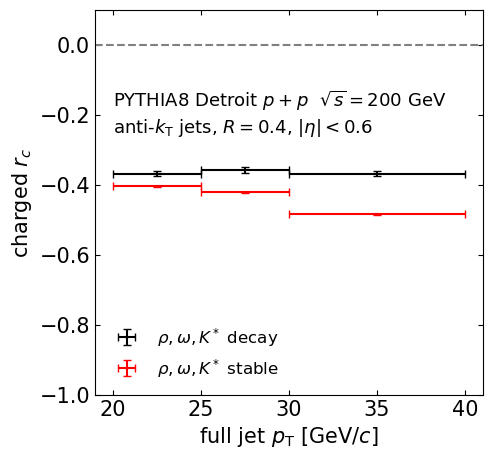

In [42]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label=r'$\rho,\omega,K^*$ decay', color='k')
plt.errorbar([22.5, 27.5, 35], stable_resonance_rc_array, xerr=[2.5, 2.5, 5], yerr=stable_resonance_rc_err_array, capsize=3, ls='none', label=r'$\rho,\omega,K^*$ stable', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'PYTHIA8 Detroit $p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-1,0.1)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')